<a href="https://colab.research.google.com/github/Akash-beep-ai/AML-Experiment/blob/main/17_08_26_AML.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Final Weight (w): 0.5688888888888889
Final Bias (b): 0.2591666666666667
Final Cost: 2.5649537037037033

Lasso Regression Equation:
Y = 0.5689X + 0.2592

Predictions:
S1: X=1.0, Actual Y=2.0, Predicted Y=0.8281
S2: X=2.0, Actual Y=3.0, Predicted Y=1.3969
S3: X=3.0, Actual Y=4.0, Predicted Y=1.9658


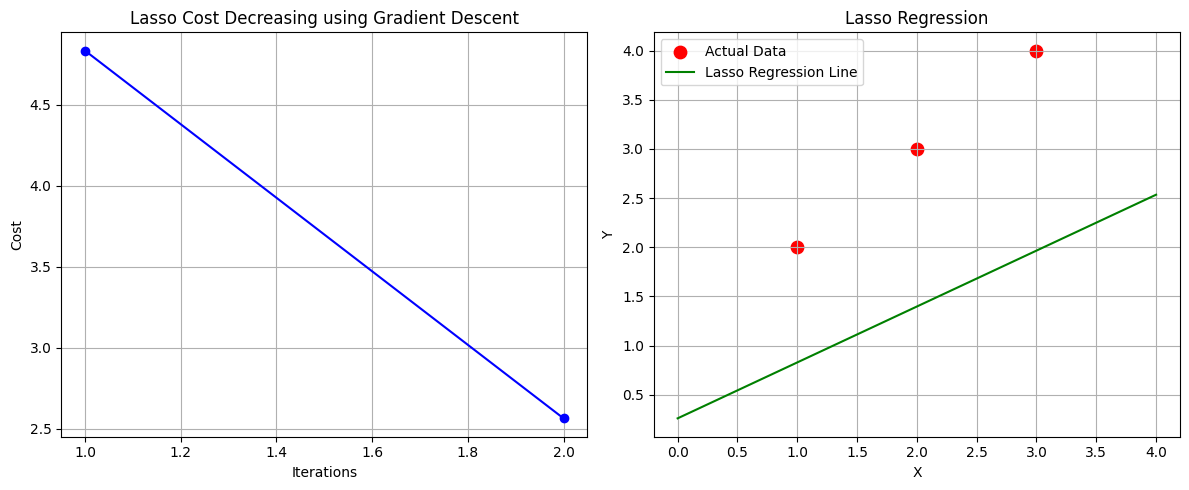


Final weight:  0.5688888888888889
Final bias:  0.2591666666666667


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

studentID = ['S1', 'S2', 'S3']

X = np.array([1, 2, 3], dtype=float)
Y = np.array([2, 3, 4], dtype=float)

m = len(X)

w = 0.0
b = 0.0

learning_rate = 0.05
iterations = 2

lambda_reg = 0.1


cost_history = []

for i in range(iterations):


    Y_pred = w * X + b

    error = Y_pred - Y

    mse_cost = (1 / (2 * m)) * np.sum(error ** 2)
    lasso_penalty = lambda_reg * abs(w)

    cost = mse_cost + lasso_penalty
    cost_history.append(cost)


    dw = (1 / m) * np.sum(error * X)


    dw = dw + lambda_reg * np.sign(w)

    db = (1 / m) * np.sum(error)


    w = w - learning_rate * dw
    b = b - learning_rate * db


print("Final Weight (w):", w)
print("Final Bias (b):", b)
print("Final Cost:", cost_history[-1])

print("\nLasso Regression Equation:")
print(f"Y = {w:.4f}X + {b:.4f}")


Y_pred = w * X + b

print("\nPredictions:")

for sid, x, actual, predicted in zip(studentID, X, Y, Y_pred):
    print(
        f"{sid}: X={x}, Actual Y={actual}, "
        f"Predicted Y={predicted:.4f}"
    )


plt.figure(figsize=(12, 5))


plt.subplot(1, 2, 1)

plt.plot(
    range(1, iterations + 1),
    cost_history,
    color='blue',
    marker='o'
)

plt.xlabel("Iterations")
plt.ylabel("Cost")
plt.title("Lasso Cost Decreasing using Gradient Descent")
plt.grid(True)


plt.subplot(1, 2, 2)

plt.scatter(
    X,
    Y,
    color='red',
    s=80,
    label='Actual Data'
)

x_line = np.linspace(0, 4, 100)
y_line = w * x_line + b

plt.plot(
    x_line,
    y_line,
    color='green',
    label='Lasso Regression Line'
)

plt.xlabel("X")
plt.ylabel("Y")
plt.title("Lasso Regression")
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


print("\nFinal weight: ", w)
print("Final bias: ", b)